In [1]:
# Import the libraries we need
import os
import re
import html
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%pip install sentence-transformers
import seaborn as sns
from sentence_transformers import SentenceTransformer
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

   ---------------------------------------- 0.0/780.3 kB ? eta -:--:--
    --------------------------------------- 10.2/780.3 kB ? eta -:--:--
   - ------------------------------------- 30.7/780.3 kB 660.6 kB/s eta 0:00:02
   -- ------------------------------------ 41.0/780.3 kB 393.8 kB/s eta 0:00:02
   --- ----------------------------------- 71.7/780.3 kB 491.5 kB/s eta 0:00:02
   ----- -------------------------------- 112.6/780.3 kB 595.3 kB/s eta 0:00:02
   --------- ---------------------------- 194.6/780.3 kB 841.6 kB/s eta 0:00:01
   ---------- --------------------------- 225.3/780.3 kB 860.2 kB/s eta 0:00:01
   -------------- ----------------------- 307.2/780.3 kB 951.8 kB/s eta 0:00:01
   ------------------------ --------------- 481.3/780.3 kB 1.4 MB/s eta 0:00:01
   --------------------------- ------------ 542.7/780.3 kB 1.3 MB/s eta 0:00:01
   -------------------------------------- - 757.8/780.3 kB 1.7 MB/s eta 0:00:01
   ---------------------------------------  778.2/780.3 k

In [2]:
# Folders and settings
DATA_DIR = "data"
MODEL_DIR = "models"
os.makedirs(MODEL_DIR, exist_ok=True)

LABELS = {1: "World", 2: "Sports", 3: "Business", 4: "Sci/Tech"}
LABEL_NAMES = ["World", "Sports", "Business", "Sci/Tech"]
EMB_MODEL = "all-MiniLM-L6-v2"   # small sentence embedding model
SEED = 42

In [3]:
# Clean a headline: fix html symbols and remove the news source at the end, like (Reuters)
def clean_text(text):
    text = re.sub(r"\s?#39;", "'", str(text)).replace("quot;", '"')
    text = html.unescape(text)
    text = re.sub(r"<[^>]+>", " ", text)          # remove html tags
    text = text.replace("\\", " ")
    text = re.sub(r"\s*\([^)]*\)\s*$", "", text)  # remove (Reuters), (AFP), ...
    text = re.sub(r"\s+", " ", text)
    return text.strip()

print(clean_text("Wall St. Bears Claw Back Into the Black (Reuters)"))

Wall St. Bears Claw Back Into the Black


In [4]:
# Load the AG News data. We use the headline (title) only, not the description
columns = ["label_id", "title", "description"]
train_df = pd.read_csv(f"{DATA_DIR}/train.csv", header=None, names=columns)
test_df = pd.read_csv(f"{DATA_DIR}/test.csv", header=None, names=columns)

for df in [train_df, test_df]:
    df["text"] = df["title"].apply(clean_text)
    df["label"] = df["label_id"].map(LABELS)

train_df = train_df[["text", "label"]]
test_df = test_df[["text", "label"]]

# Remove empty and duplicate headlines from the training data
train_df = train_df[train_df["text"].str.len() > 0].drop_duplicates()

print("train:", train_df.shape, " test:", test_df.shape)
train_df.head()

train: (111447, 2)  test: (7600, 2)


,text,label
0,Wall St. Bears Claw Back Into the Black,Business
1,Carlyle Looks Toward Commercial Aerospace,Business
2,Oil and Economy Cloud Stocks' Outlook,Business
3,Iraq Halts Oil Exports from Main Southern Pipe...,Business
4,"Oil prices soar to all-time record, posing new...",Business


In [5]:
# Split the training data: 90% train, 10% dev (dev is used to choose the best settings)
train, dev = train_test_split(train_df, test_size=0.1, stratify=train_df["label"], random_state=SEED)
print("train:", len(train), " dev:", len(dev), " test:", len(test_df))
train["label"].value_counts()

train: 100302  dev: 11145  test: 7600


label
Sports      25995
World       25381
Business    24819
Sci/Tech    24107
Name: count, dtype: int64

In [6]:
# Load the embedding model (it turns each headline into a vector of 384 numbers)
encoder = SentenceTransformer(EMB_MODEL)

# Encode the headlines. The vectors are saved in the data folder, so next time we just load them
def get_embeddings(df, name):
    path = f"{DATA_DIR}/emb_{name}.npy"
    if os.path.exists(path):
        emb = np.load(path)
        if len(emb) == len(df):
            return emb
    emb = encoder.encode(df["text"].tolist(), batch_size=128, show_progress_bar=True, normalize_embeddings=True)
    np.save(path, emb)
    return emb

X_train = get_embeddings(train, "train")
X_dev = get_embeddings(dev, "dev")
X_test = get_embeddings(test_df, "test")
print("train:", X_train.shape, " dev:", X_dev.shape, " test:", X_test.shape)

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

train: (100302, 384)  dev: (11145, 384)  test: (7600, 384)


In [7]:
# Training: try a few values of C and keep the one with the best F1 on the dev set
best_f1 = 0
best_model = None

for C in [1, 5, 10]:
    model = LogisticRegression(C=C, max_iter=2000)
    model.fit(X_train, train["label"])

    pred = model.predict(X_dev)
    acc = accuracy_score(dev["label"], pred)
    f1 = f1_score(dev["label"], pred, average="macro")
    print(f"C={C}  ->  acc={acc:.4f}  f1={f1:.4f}")

    if f1 > best_f1:
        best_f1 = f1
        best_model = model
        best_C = C

print("\nBest C:", best_C, " dev F1:", round(best_f1, 4))

C=1  ->  acc=0.8256  f1=0.8244
C=5  ->  acc=0.8257  f1=0.8246
C=10  ->  acc=0.8245  f1=0.8234

Best C: 5  dev F1: 0.8246


In [8]:
# Save the best model in the models folder
joblib.dump(best_model, f"{MODEL_DIR}/emb_lr.joblib")
print("model saved")

model saved


In [9]:
# Testing: evaluate the best model on the test set (used only once, at the end)
y_test = test_df["label"]
y_pred = best_model.predict(X_test)

print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("Macro F1:", round(f1_score(y_test, y_pred, average="macro"), 4))
print()
print(classification_report(y_test, y_pred, labels=LABEL_NAMES, digits=4))

Accuracy: 0.8287
Macro F1: 0.8285

              precision    recall  f1-score   support

       World     0.8558    0.8374    0.8465      1900
      Sports     0.8724    0.8926    0.8824      1900
    Business     0.7786    0.7737    0.7761      1900
    Sci/Tech     0.8072    0.8111    0.8091      1900

    accuracy                         0.8287      7600
   macro avg     0.8285    0.8287    0.8285      7600
weighted avg     0.8285    0.8287    0.8285      7600



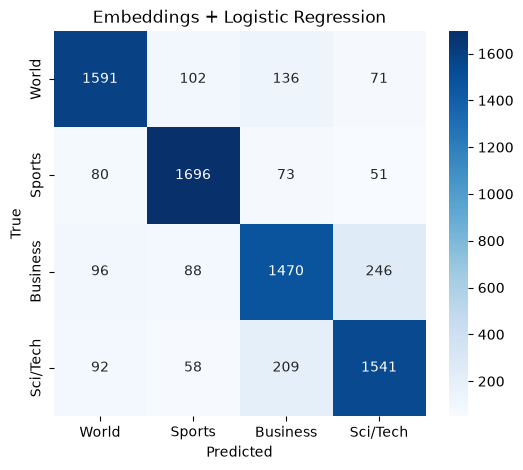

In [10]:
# Confusion matrix: rows are the true topic, columns are the predicted topic
cm = confusion_matrix(y_test, y_pred, labels=LABEL_NAMES)

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=LABEL_NAMES, yticklabels=LABEL_NAMES)
plt.title("Embeddings + Logistic Regression")
plt.xlabel("Predicted")
plt.ylabel("True")
plt.show()

In [11]:
# Error analysis: Business and World are the topics the model mixes up the most
results = test_df.copy()
results["pred"] = y_pred

print("Business -> World:", ((results["label"] == "Business") & (results["pred"] == "World")).sum())
print("World -> Business:", ((results["label"] == "World") & (results["pred"] == "Business")).sum())

mistakes = results[(results["label"] != results["pred"]) & results["label"].isin(["Business", "World"])]
mistakes.head(10)

Business -> World: 96
World -> Business: 136


,text,label,pred
33,"Man Sought #36;50M From McGreevey, Aides Say",World,Business
37,1994 Law Designed to Preserve Guard Jobs,World,Business
56,India's Tata expands regional footprint via Na...,World,Business
67,Jackson Squares Off With Prosecutor,World,Sports
79,Live: Olympics day four,World,Sports
83,Intel to delay product aimed for high-definiti...,Business,Sci/Tech
88,U.S. Misses Cut in Olympic 100 Free,World,Sports
103,Surviving Biotech's Downturns,Business,Sci/Tech
104,Mr Downer shoots his mouth off,World,Sports
106,Stocks Climb on Drop in Consumer Prices,World,Business


In [12]:
# Accuracy by headline length (number of words)
results["words"] = results["text"].str.split().str.len()
results["length"] = pd.cut(results["words"], bins=[0, 5, 8, 100], labels=["<=5", "6-8", ">8"])
results["correct"] = results["label"] == results["pred"]
results.groupby("length", observed=True)["correct"].agg(["count", "mean"]).round(4)

,count,mean
length,,
<=5,2377,0.7993
6-8,4079,0.8345
>8,1144,0.8689


In [13]:
# Try the model on new headlines
headlines = [
    "Oil prices jump after OPEC cuts production",
    "Real Madrid beat Barcelona 2-1 in El Clasico",
    "Apple unveils new chip for faster AI on phones",
]
emb = encoder.encode([clean_text(h) for h in headlines], normalize_embeddings=True)
for h, p in zip(headlines, best_model.predict(emb)):
    print(p, " <- ", h)

Business  <-  Oil prices jump after OPEC cuts production
Sports  <-  Real Madrid beat Barcelona 2-1 in El Clasico
Sci/Tech  <-  Apple unveils new chip for faster AI on phones
